# Bước 4 - Trừu tượng hóa dữ liệu (Data Visualization)

Công cụ sử dụng: **Python 3 - matplotlib.pyplot + seaborn** (đúng 2 thư viện đã học).
Mỗi biểu đồ là 1 cell riêng, theo đúng cấu trúc 4 bước:

```
# B1: Chuẩn bị dữ liệu
# B2: Khởi tạo đồ thị
# B3: Trang trí, định dạng
# B4: Show lên cho người ta coi
plt.show()
```

Tổng cộng **16 biểu đồ**, **15 loại khác nhau**, **7 biểu đồ dựa trên dữ liệu tổng hợp**
(group by / value_counts / pivot / crosstab). Mọi số liệu trong phần nhận xét được tính
trực tiếp từ `DATA/after_python.csv` (không bịa số liệu).

## Thiết lập: import thư viện & đọc dữ liệu

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Bảng màu & theme dùng chung cho mọi biểu đồ
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_BLUE = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#1c5cab", "#0d366b"]
SURFACE, INK, INK2, MUTED, GRID, BASELINE = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "text.color": INK, "axes.labelcolor": INK2, "axes.edgecolor": BASELINE,
    "xtick.color": MUTED, "ytick.color": MUTED, "grid.color": GRID,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlecolor": INK,
    "font.size": 10, "font.family": "DejaVu Sans",
})
sns.set_style("whitegrid", {"axes.facecolor": SURFACE, "grid.color": GRID})

EDU_ORDER = ["Basic", "2n Cycle", "Graduation", "Master", "PhD"]
MNT_COLS = ["MntWines", "MntFruits", "MntMeatProducts", "MntFishProducts", "MntSweetProducts", "MntGoldProds"]

df = pd.read_csv("../DATA/after_python.csv")
df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"])
df["Age"] = 2014 - df["Year_Birth"]
df["Total_Spending"] = df[MNT_COLS].sum(axis=1)
df["Enroll_YearMonth"] = df["Dt_Customer"].dt.to_period("M")
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,Response,Income_smoothed,Education_encoded,Marital_Status_encoded,Campaigns_Response_Bitmask,Products_Purchased,Product_Categories_Bitmask,Age,Total_Spending,Enroll_YearMonth
0,5524.0,1957.0,Graduation,Single,58138.0,0.0,0.0,2012-09-04,58.0,635.0,...,1,51918.08,2,4,64,"Wines, Fruits, Meat, Fish, Sweet, Gold",63,57.0,1617.0,2012-09
1,2174.0,1954.0,Graduation,Married,46344.0,1.0,1.0,2014-03-08,38.0,11.0,...,0,51918.08,2,3,0,"Wines, Fruits, Meat, Fish, Sweet, Gold",63,60.0,27.0,2014-03
2,6182.0,1984.0,Graduation,Together,26646.0,1.0,0.0,2014-02-10,26.0,11.0,...,0,51918.08,2,5,0,"Wines, Fruits, Meat, Fish, Sweet, Gold",63,30.0,53.0,2014-02
3,5324.0,1981.0,PhD,Married,58293.0,1.0,0.0,2014-01-19,94.0,173.0,...,0,51918.08,4,3,0,"Wines, Fruits, Meat, Fish, Sweet, Gold",63,33.0,422.0,2014-01
4,7446.0,1967.0,Master,Together,62513.0,0.0,1.0,2013-09-09,16.0,520.0,...,0,51918.08,3,5,0,"Wines, Fruits, Meat, Sweet, Gold",55,47.0,716.0,2013-09


## 1. Histogram - Phân phối Income
**Loại biểu đồ:** Histogram  |  **Dữ liệu tổng hợp:** Không

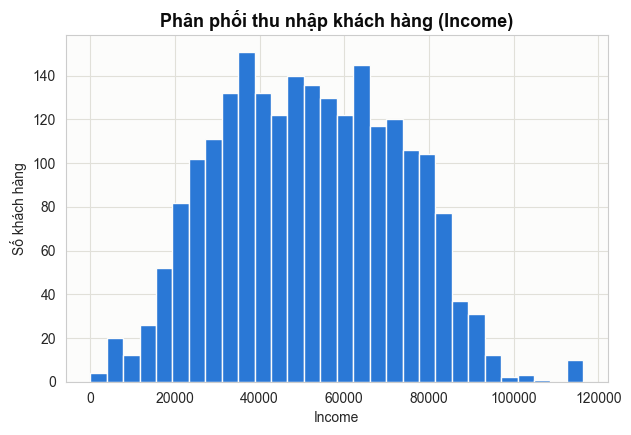

In [2]:
# B1: Chuẩn bị dữ liệu
data = df["Income"]

# B2: Khởi tạo đồ thị
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.hist(data, bins=30, color=CAT[0], edgecolor=SURFACE)

# B3: Trang trí, định dạng
ax.set_title("Phân phối thu nhập khách hàng (Income)")
ax.set_xlabel("Income")
ax.set_ylabel("Số khách hàng")

# B4: Show lên cho người ta coi
plt.savefig("../04_Charts/images/01_histogram_income.png", dpi=150, bbox_inches="tight")
plt.show()

**Nhận xét:** Phân phối Income lệch phải nhẹ (mean > median), tập trung chủ yếu trong khoảng 35.000-68.000 (IQR), phần lớn khách hàng có thu nhập trung bình-khá.

## 2. Boxplot - MntWines theo Education
**Loại biểu đồ:** Boxplot  |  **Dữ liệu tổng hợp:** Không

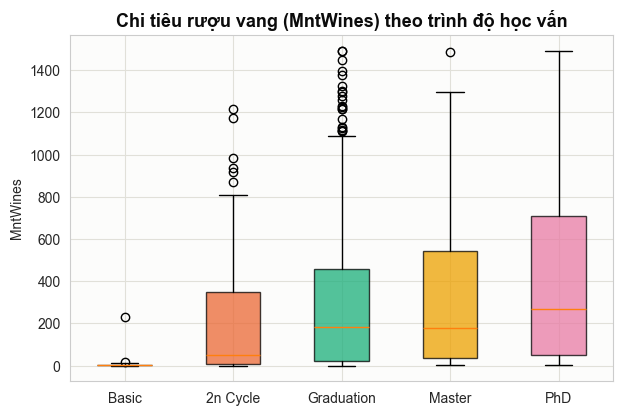

In [3]:
# B1: Chuẩn bị dữ liệu
data_by_edu = [df.loc[df["Education"] == e, "MntWines"] for e in EDU_ORDER]

# B2: Khởi tạo đồ thị
fig, ax = plt.subplots(figsize=(7, 4.5))
bp = ax.boxplot(data_by_edu, tick_labels=EDU_ORDER, patch_artist=True, showfliers=True)

# B3: Trang trí, định dạng
for patch, c in zip(bp["boxes"], CAT):
    patch.set_facecolor(c)
    patch.set_alpha(0.75)
ax.set_title("Chi tiêu rượu vang (MntWines) theo trình độ học vấn")
ax.set_ylabel("MntWines")

# B4: Show lên cho người ta coi
plt.savefig("../04_Charts/images/02_boxplot_wines_by_education.png", dpi=150, bbox_inches="tight")
plt.show()

**Nhận xét:** Median chi tiêu rượu vang tăng dần theo trình độ học vấn cao hơn; khoảng tứ phân vị (IQR) cũng rộng hơn ở các nhóm học vấn cao, kèm nhiều outlier phía trên do một số khách hàng chi tiêu vượt trội.

## 3. Bar chart - value_counts(Education)
**Loại biểu đồ:** Bar chart  |  **Dữ liệu tổng hợp:** Có

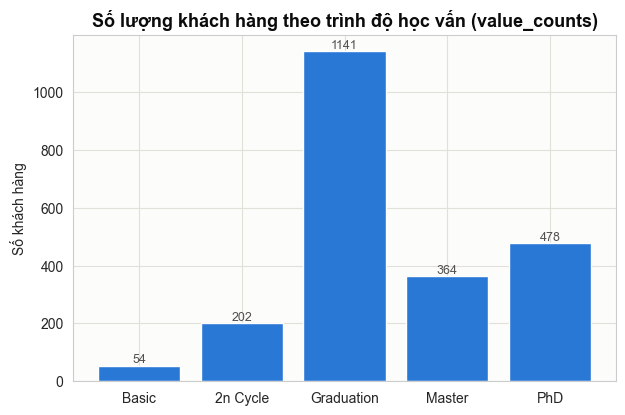

In [4]:
# B1: Chuẩn bị dữ liệu
vc_edu = df["Education"].value_counts().reindex(EDU_ORDER)

# B2: Khởi tạo đồ thị
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(vc_edu.index, vc_edu.values, color=CAT[0])

# B3: Trang trí, định dạng
ax.set_title("Số lượng khách hàng theo trình độ học vấn (value_counts)")
ax.set_ylabel("Số khách hàng")
for i, v in enumerate(vc_edu.values):
    ax.text(i, v + 10, str(v), ha="center", color=INK2, fontsize=9)

# B4: Show lên cho người ta coi
plt.savefig("../04_Charts/images/03_bar_education_valuecounts.png", dpi=150, bbox_inches="tight")
plt.show()

**Nhận xét:** 'Graduation' chiếm tỉ trọng lớn nhất trong 5 nhóm học vấn, trong khi 'Basic' chiếm tỉ trọng thấp nhất - cho thấy phần lớn khách hàng có trình độ từ Graduation trở lên.

## 4. Pie chart - value_counts(Marital_Status)
**Loại biểu đồ:** Pie chart  |  **Dữ liệu tổng hợp:** Có

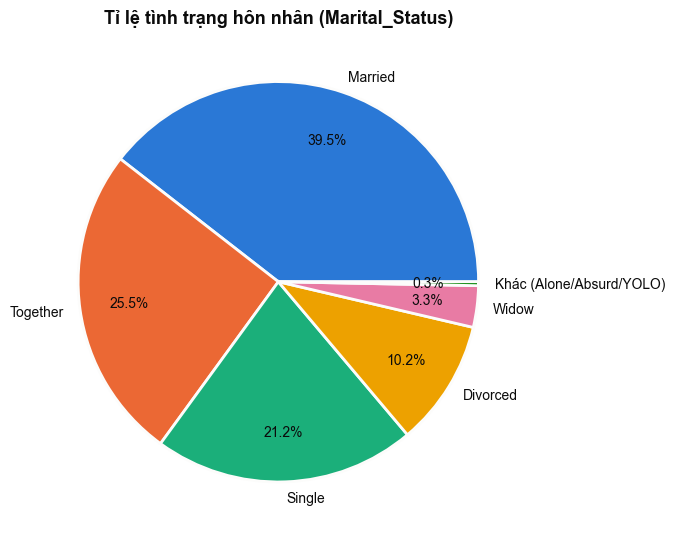

In [5]:
# B1: Chuẩn bị dữ liệu
vc_ms_raw = df["Marital_Status"].value_counts()
RARE_GROUPS = ["Alone", "Absurd", "YOLO"]
vc_ms = vc_ms_raw.drop(index=[g for g in RARE_GROUPS if g in vc_ms_raw.index])
vc_ms["Khác (Alone/Absurd/YOLO)"] = vc_ms_raw.reindex(RARE_GROUPS).fillna(0).sum()
vc_ms = vc_ms.sort_values(ascending=False)

# B2: Khởi tạo đồ thị
fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.pie(vc_ms.values, labels=vc_ms.index, autopct="%1.1f%%", colors=CAT,
       wedgeprops=dict(edgecolor=SURFACE, linewidth=2), textprops=dict(color=INK),
       labeldistance=1.08, pctdistance=0.75)

# B3: Trang trí, định dạng
ax.set_title("Tỉ lệ tình trạng hôn nhân (Marital_Status)")

# B4: Show lên cho người ta coi
plt.savefig("../04_Charts/images/04_pie_marital_status.png", dpi=150, bbox_inches="tight")
plt.show()

**Nhận xét:** 'Married' chiếm tỉ trọng cao nhất; 3 nhóm hiếm (Alone/Absurd/YOLO) cộng lại chỉ chiếm một phần rất nhỏ - là các giá trị đặc thù vốn có trong dữ liệu gốc, không phải lỗi nhập liệu.

## 5. Line chart - Xu hướng đăng ký theo tháng (groupby tháng)
**Loại biểu đồ:** Line chart  |  **Dữ liệu tổng hợp:** Có

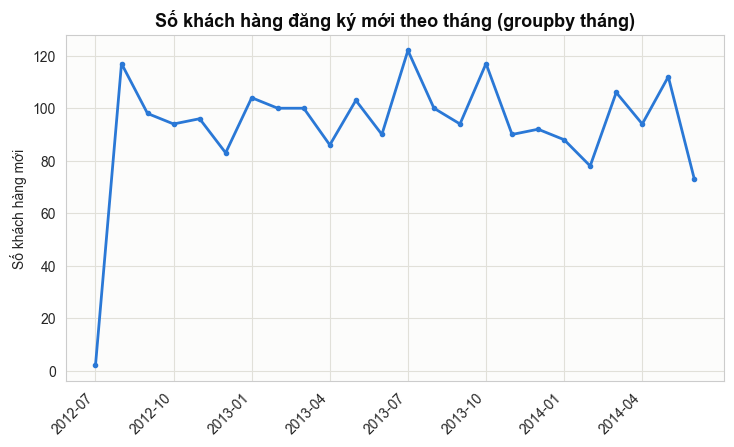

In [6]:
# B1: Chuẩn bị dữ liệu
monthly = df.groupby("Enroll_YearMonth").size()

# B2: Khởi tạo đồ thị
fig, ax = plt.subplots(figsize=(8.5, 4.5))
ax.plot(monthly.index.astype(str), monthly.values, color=CAT[0], linewidth=2, marker="o", markersize=3)

# B3: Trang trí, định dạng
ax.set_title("Số khách hàng đăng ký mới theo tháng (groupby tháng)")
ax.set_ylabel("Số khách hàng mới")
ax.set_xticks(range(0, len(monthly), 3))
ax.set_xticklabels([monthly.index.astype(str)[i] for i in range(0, len(monthly), 3)], rotation=45, ha="right")

# B4: Show lên cho người ta coi
plt.savefig("../04_Charts/images/05_line_enrollment_trend.png", dpi=150, bbox_inches="tight")
plt.show()

**Nhận xét:** Số khách hàng đăng ký mới khá ổn định qua các tháng, không có tháng nào tăng/giảm đột biến bất thường trong suốt giai đoạn ghi nhận.

## 6. Scatter plot - Income vs MntWines
**Loại biểu đồ:** Scatter plot  |  **Dữ liệu tổng hợp:** Không

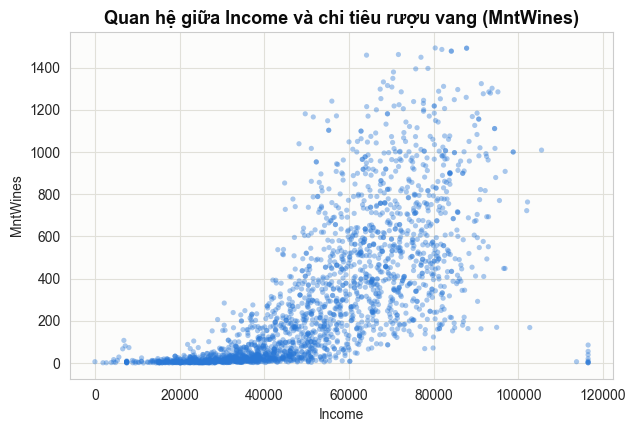

In [7]:
# B1: Chuẩn bị dữ liệu
x = df["Income"]
y = df["MntWines"]

# B2: Khởi tạo đồ thị
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(x, y, s=14, alpha=0.4, color=CAT[0], edgecolor="none")

# B3: Trang trí, định dạng
ax.set_title("Quan hệ giữa Income và chi tiêu rượu vang (MntWines)")
ax.set_xlabel("Income")
ax.set_ylabel("MntWines")

# B4: Show lên cho người ta coi
plt.savefig("../04_Charts/images/06_scatter_income_vs_wines.png", dpi=150, bbox_inches="tight")
plt.show()

**Nhận xét:** Các điểm có xu hướng đi lên rõ rệt: khách hàng có thu nhập cao hơn có xu hướng chi tiêu nhiều hơn cho rượu vang (tương quan dương).

## 7. Heatmap - Ma trận tương quan chi tiêu & Income
**Loại biểu đồ:** Heatmap  |  **Dữ liệu tổng hợp:** Có

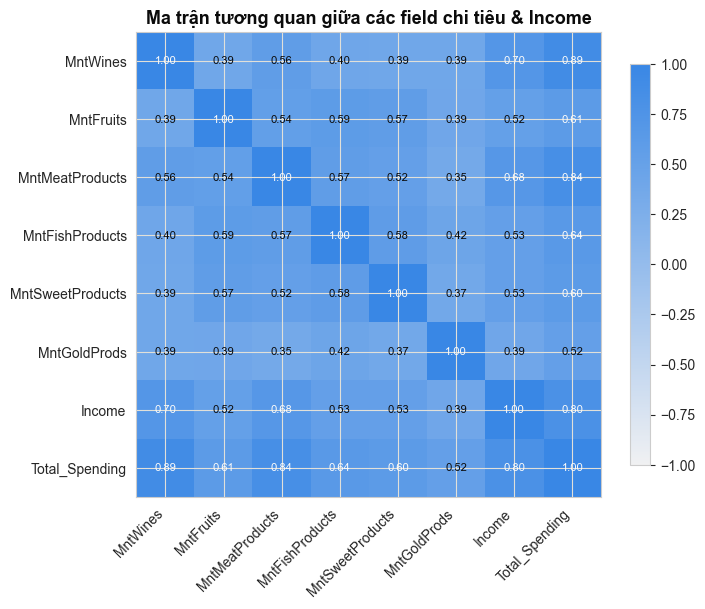

In [8]:
# B1: Chuẩn bị dữ liệu
corr_cols = MNT_COLS + ["Income", "Total_Spending"]
corr_mat = df[corr_cols].corr()

# B2: Khởi tạo đồ thị
fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(corr_mat.values, cmap=sns.light_palette(SEQ_BLUE[3], as_cmap=True), vmin=-1, vmax=1)

# B3: Trang trí, định dạng
ax.set_xticks(range(len(corr_cols)))
ax.set_yticks(range(len(corr_cols)))
ax.set_xticklabels(corr_cols, rotation=45, ha="right")
ax.set_yticklabels(corr_cols)
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        ax.text(j, i, f"{corr_mat.values[i, j]:.2f}", ha="center", va="center",
                color=INK if abs(corr_mat.values[i, j]) < 0.6 else SURFACE, fontsize=8)
ax.set_title("Ma trận tương quan giữa các field chi tiêu & Income")
fig.colorbar(im, ax=ax, shrink=0.8)

# B4: Show lên cho người ta coi
plt.savefig("../04_Charts/images/07_heatmap_correlation.png", dpi=150, bbox_inches="tight")
plt.show()

**Nhận xét:** Các field Mnt* (chi tiêu theo từng nhóm sản phẩm) nhìn chung tương quan dương khá mạnh với nhau, phản ánh khách hàng chi nhiều tiền thường chi đều cho nhiều nhóm sản phẩm.

## 8. Violin plot - Income theo Education
**Loại biểu đồ:** Violin plot  |  **Dữ liệu tổng hợp:** Không

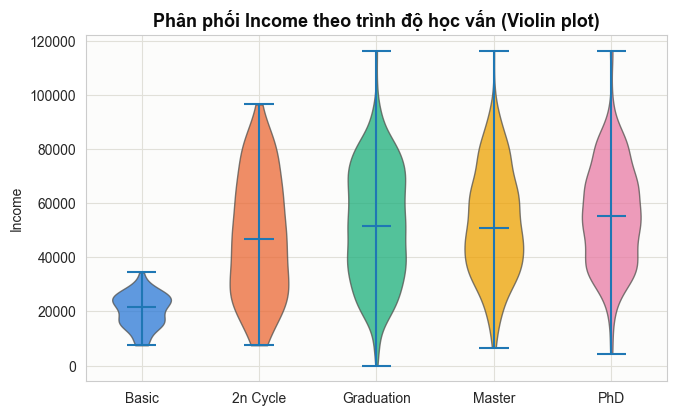

In [9]:
# B1: Chuẩn bị dữ liệu
data_by_edu = [df.loc[df["Education"] == e, "Income"] for e in EDU_ORDER]

# B2: Khởi tạo đồ thị
fig, ax = plt.subplots(figsize=(7.5, 4.5))
parts = ax.violinplot(data_by_edu, showmedians=True)

# B3: Trang trí, định dạng
for i, body in enumerate(parts["bodies"]):
    body.set_facecolor(CAT[i % len(CAT)])
    body.set_alpha(0.75)
    body.set_edgecolor(INK2)
ax.set_xticks(range(1, len(EDU_ORDER) + 1))
ax.set_xticklabels(EDU_ORDER)
ax.set_title("Phân phối Income theo trình độ học vấn (Violin plot)")
ax.set_ylabel("Income")

# B4: Show lên cho người ta coi
plt.savefig("../04_Charts/images/08_violin_income_by_education.png", dpi=150, bbox_inches="tight")
plt.show()

**Nhận xét:** Hình dạng phân phối Income khác nhau rõ rệt giữa các nhóm; nhóm 'PhD' có median Income cao nhất, 'Basic' thấp nhất - trình độ học vấn có liên hệ với mức thu nhập trong tập dữ liệu này.

## 9. Count plot - NumDealsPurchases
**Loại biểu đồ:** Count plot  |  **Dữ liệu tổng hợp:** Không

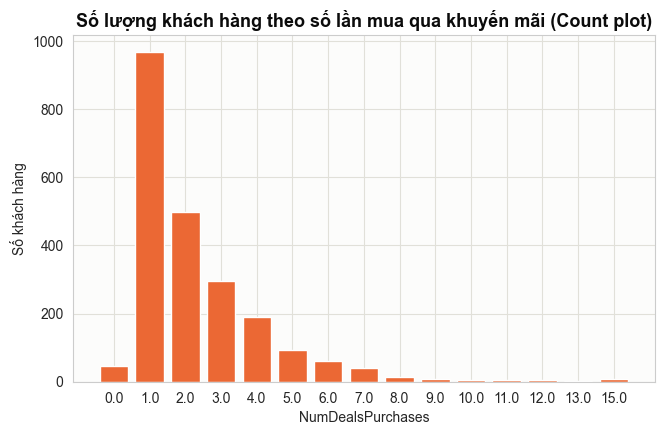

In [10]:
# B1: Chuẩn bị dữ liệu
vc_deals = df["NumDealsPurchases"].value_counts().sort_index()

# B2: Khởi tạo đồ thị
fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.bar(vc_deals.index.astype(str), vc_deals.values, color=CAT[1])

# B3: Trang trí, định dạng
ax.set_title("Số lượng khách hàng theo số lần mua qua khuyến mãi (Count plot)")
ax.set_xlabel("NumDealsPurchases")
ax.set_ylabel("Số khách hàng")

# B4: Show lên cho người ta coi
plt.savefig("../04_Charts/images/09_countplot_numdeals.png", dpi=150, bbox_inches="tight")
plt.show()

**Nhận xét:** Phân phối lệch phải: phần lớn khách hàng chỉ mua qua khuyến mãi 1-3 lần, rất ít khách hàng mua qua khuyến mãi trên 8 lần.

## 10. KDE plot - Phân phối tuổi khách hàng
**Loại biểu đồ:** KDE plot  |  **Dữ liệu tổng hợp:** Không

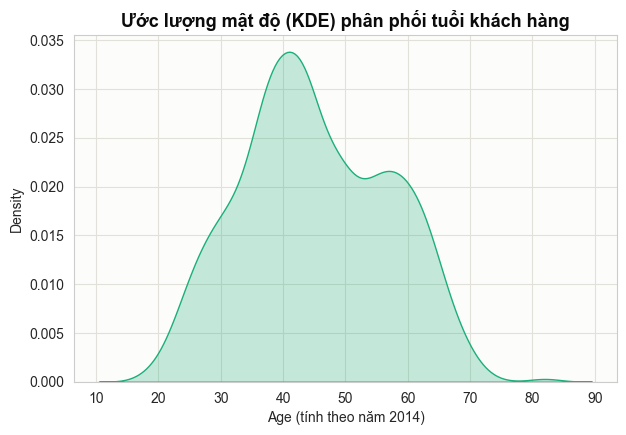

In [11]:
# B1: Chuẩn bị dữ liệu
age = df["Age"]

# B2: Khởi tạo đồ thị
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.kdeplot(age, fill=True, color=CAT[2], ax=ax)

# B3: Trang trí, định dạng
ax.set_title("Ước lượng mật độ (KDE) phân phối tuổi khách hàng")
ax.set_xlabel("Age (tính theo năm 2014)")

# B4: Show lên cho người ta coi
plt.savefig("../04_Charts/images/10_kde_age.png", dpi=150, bbox_inches="tight")
plt.show()

**Nhận xét:** Tuổi khách hàng tập trung quanh khoảng 40-50 tuổi, phân phối tương đối đối xứng sau khi đã xử lý outlier ở field Year_Birth.

## 11. Stacked bar - crosstab(Education, Marital_Status)
**Loại biểu đồ:** Stacked bar chart  |  **Dữ liệu tổng hợp:** Có

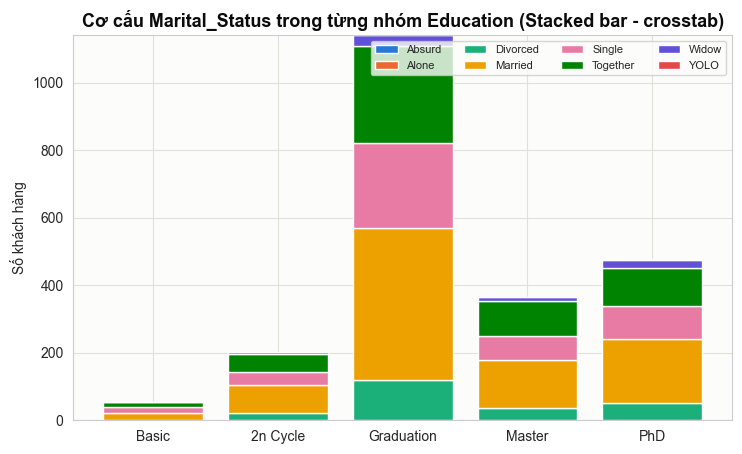

In [12]:
# B1: Chuẩn bị dữ liệu
ctab = pd.crosstab(df["Education"], df["Marital_Status"]).reindex(EDU_ORDER)

# B2: Khởi tạo đồ thị
fig, ax = plt.subplots(figsize=(8.5, 5))
bottom = np.zeros(len(ctab))
for i, col in enumerate(ctab.columns):
    ax.bar(ctab.index, ctab[col], bottom=bottom, label=col, color=CAT[i % len(CAT)])
    bottom += ctab[col].values

# B3: Trang trí, định dạng
ax.set_title("Cơ cấu Marital_Status trong từng nhóm Education (Stacked bar - crosstab)")
ax.set_ylabel("Số khách hàng")
ax.legend(fontsize=8, ncol=4, loc="upper right")

# B4: Show lên cho người ta coi
plt.savefig("../04_Charts/images/11_stacked_bar_education_marital.png", dpi=150, bbox_inches="tight")
plt.show()

**Nhận xét:** Ở mọi nhóm học vấn, 'Married' và 'Together' luôn là 2 nhóm chiếm tỉ trọng lớn nhất, cho thấy cơ cấu hôn nhân khá đồng đều giữa các nhóm trình độ học vấn, không có khác biệt cấu trúc rõ rệt.

## 12. Grouped bar - groupby(Education).mean()
**Loại biểu đồ:** Grouped bar chart  |  **Dữ liệu tổng hợp:** Có

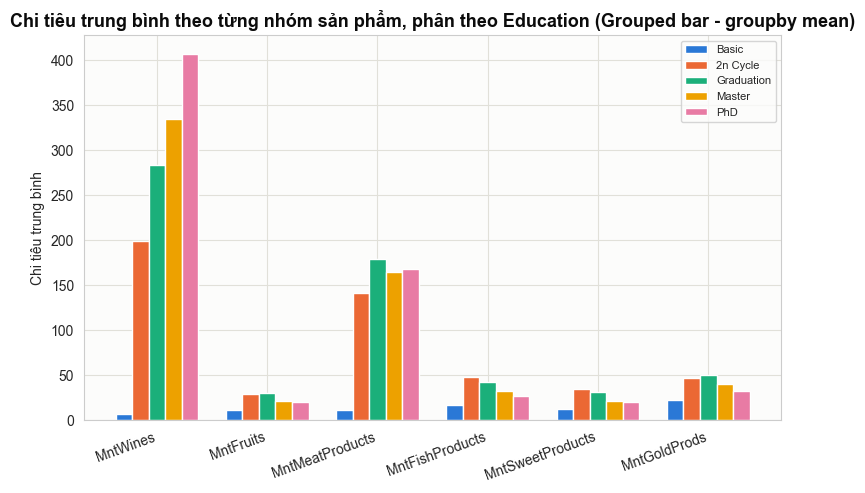

In [13]:
# B1: Chuẩn bị dữ liệu
avg_spend = df.groupby("Education")[MNT_COLS].mean().reindex(EDU_ORDER)

# B2: Khởi tạo đồ thị
fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(MNT_COLS))
width = 0.15
for i, edu in enumerate(EDU_ORDER):
    ax.bar(x + i * width, avg_spend.loc[edu].values, width=width, label=edu, color=CAT[i % len(CAT)])

# B3: Trang trí, định dạng
ax.set_xticks(x + width * 2)
ax.set_xticklabels(MNT_COLS, rotation=20, ha="right")
ax.set_title("Chi tiêu trung bình theo từng nhóm sản phẩm, phân theo Education (Grouped bar - groupby mean)")
ax.set_ylabel("Chi tiêu trung bình")
ax.legend(fontsize=8)

# B4: Show lên cho người ta coi
plt.savefig("../04_Charts/images/12_grouped_bar_avg_spend_education.png", dpi=150, bbox_inches="tight")
plt.show()

**Nhận xét:** 'PhD' và 'Master' chi tiêu trung bình cao hơn các nhóm còn lại ở hầu hết các loại sản phẩm, phù hợp với việc nhóm này cũng có Income trung bình cao hơn.

## 13. Area chart - Tổng chi tiêu tích luỹ theo tháng (groupby + cumsum)
**Loại biểu đồ:** Area chart  |  **Dữ liệu tổng hợp:** Có

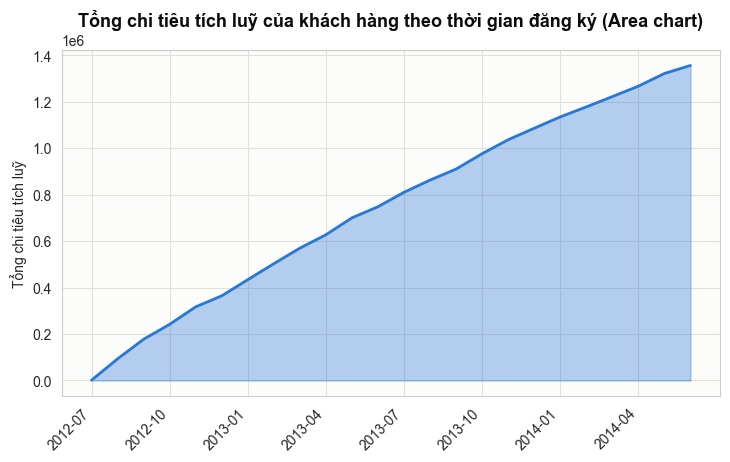

In [14]:
# B1: Chuẩn bị dữ liệu
monthly_spend = df.groupby("Enroll_YearMonth")["Total_Spending"].sum().sort_index()
cum_spend = monthly_spend.cumsum()

# B2: Khởi tạo đồ thị
fig, ax = plt.subplots(figsize=(8.5, 4.5))
ax.fill_between(cum_spend.index.astype(str), cum_spend.values, color=CAT[0], alpha=0.35)
ax.plot(cum_spend.index.astype(str), cum_spend.values, color=CAT[0], linewidth=2)

# B3: Trang trí, định dạng
ax.set_title("Tổng chi tiêu tích luỹ của khách hàng theo thời gian đăng ký (Area chart)")
ax.set_ylabel("Tổng chi tiêu tích luỹ")
ax.set_xticks(range(0, len(cum_spend), 3))
ax.set_xticklabels([cum_spend.index.astype(str)[i] for i in range(0, len(cum_spend), 3)], rotation=45, ha="right")

# B4: Show lên cho người ta coi
plt.savefig("../04_Charts/images/13_area_cumulative_spending.png", dpi=150, bbox_inches="tight")
plt.show()

**Nhận xét:** Tổng chi tiêu tích luỹ tăng đều qua các tháng, phù hợp với tốc độ đăng ký khách hàng mới khá ổn định quan sát được ở biểu đồ Line chart.

## 14. Horizontal bar - Tổng chi tiêu theo nhóm sản phẩm (groupby sum)
**Loại biểu đồ:** Horizontal bar chart  |  **Dữ liệu tổng hợp:** Có

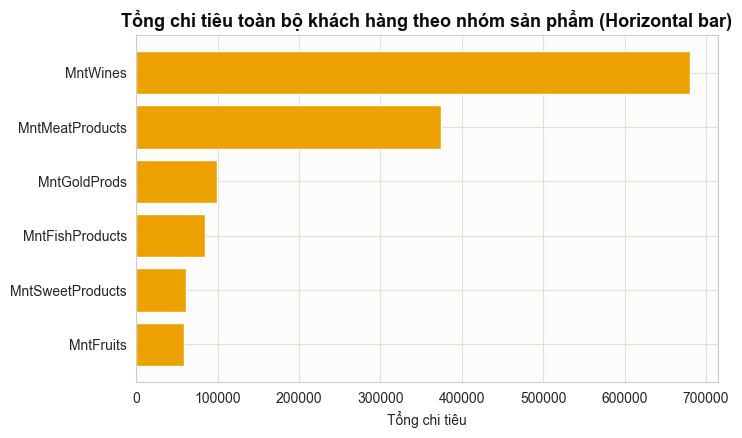

In [15]:
# B1: Chuẩn bị dữ liệu
total_by_product = df[MNT_COLS].sum().sort_values()

# B2: Khởi tạo đồ thị
fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.barh(total_by_product.index, total_by_product.values, color=CAT[3])

# B3: Trang trí, định dạng
ax.set_title("Tổng chi tiêu toàn bộ khách hàng theo nhóm sản phẩm (Horizontal bar)")
ax.set_xlabel("Tổng chi tiêu")

# B4: Show lên cho người ta coi
plt.savefig("../04_Charts/images/14_hbar_total_spend_by_product.png", dpi=150, bbox_inches="tight")
plt.show()

**Nhận xét:** 'MntWines' là nhóm sản phẩm có tổng doanh thu cao nhất, vượt trội hẳn so với các nhóm sản phẩm còn lại.

## 15. Regression plot - Income vs Total_Spending
**Loại biểu đồ:** Regression plot  |  **Dữ liệu tổng hợp:** Không

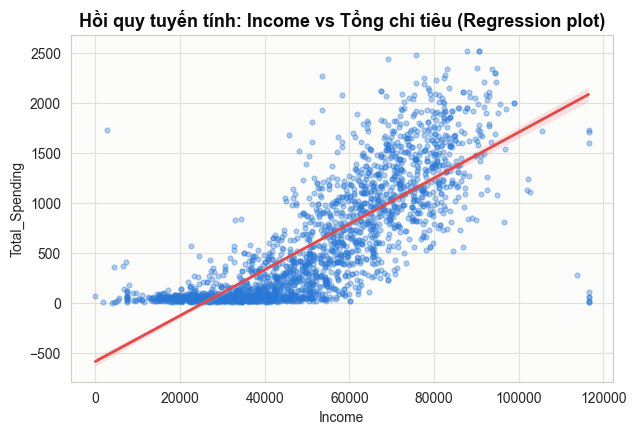

In [16]:
# B1: Chuẩn bị dữ liệu
# (sns.regplot tự xử lý dữ liệu đầu vào trực tiếp từ DataFrame df)

# B2: Khởi tạo đồ thị
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.regplot(x="Income", y="Total_Spending", data=df, ax=ax,
            scatter_kws=dict(s=12, alpha=0.35, color=CAT[0]),
            line_kws=dict(color=CAT[7], linewidth=2))

# B3: Trang trí, định dạng
ax.set_title("Hồi quy tuyến tính: Income vs Tổng chi tiêu (Regression plot)")

# B4: Show lên cho người ta coi
plt.savefig("../04_Charts/images/15_regplot_income_totalspend.png", dpi=150, bbox_inches="tight")
plt.show()

**Nhận xét:** Tương quan tuyến tính mạnh giữa Income và tổng chi tiêu, đường hồi quy có hệ số góc dương rõ rệt, xác nhận Income là yếu tố dự báo quan trọng cho hành vi chi tiêu.

## 16. Heatmap - Missingness trước khi làm sạch (bonus)
**Loại biểu đồ:** Heatmap (missingness)  |  **Dữ liệu tổng hợp:** Không

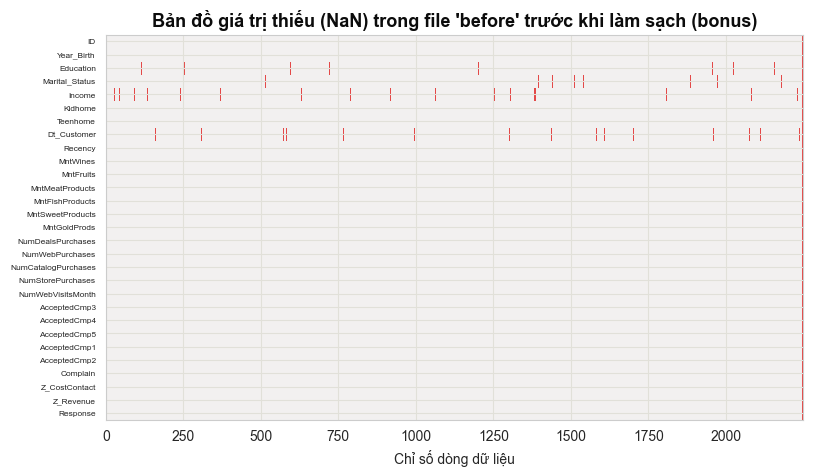

In [17]:
# B1: Chuẩn bị dữ liệu
before = pd.read_csv("../DATA/NguyenQuocHung_customer_personality.csv")
miss = before.isna().astype(int)

# B2: Khởi tạo đồ thị
fig, ax = plt.subplots(figsize=(9, 5))
ax.imshow(miss.T.values, aspect="auto", cmap=sns.light_palette(CAT[7], as_cmap=True), interpolation="none")

# B3: Trang trí, định dạng
ax.set_yticks(range(len(miss.columns)))
ax.set_yticklabels(miss.columns, fontsize=6)
ax.set_xlabel("Chỉ số dòng dữ liệu")
ax.set_title("Bản đồ giá trị thiếu (NaN) trong file 'before' trước khi làm sạch (bonus)")

# B4: Show lên cho người ta coi
plt.savefig("../04_Charts/images/16_missingness_heatmap_before.png", dpi=150, bbox_inches="tight")
plt.show()

**Nhận xét:** Giá trị thiếu (NaN) tập trung nhiều nhất ở Income, Education, Marital_Status, Dt_Customer - đúng như mô tả lỗi đã được chèn vào dữ liệu 'before'.